<div data-bmll-brand="notebook-header" style="display:flex;justify-content:space-between;align-items:center;padding:0 0 12px;border-bottom:2px solid #146BC1;margin-bottom:18px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
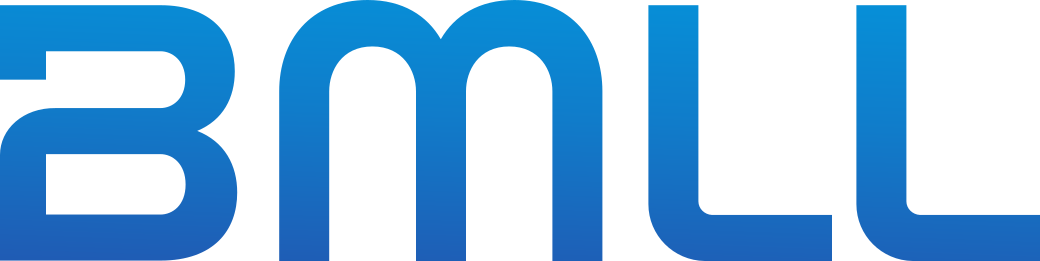
<span style="color:#878786;font-size:11px;"></span>
</div>


# TCA Using BMLL

Scoped execution cost and trade-anchored markout analysis using bmll.data.query.

**Environment:** BMLL Query API

In [2]:
# BMLL notebook style helpers. Generated from inputs/bmll-notebook-branding.
BMLL_COLOURS = {
    'primary': {'blue_1': '#333396', 'blue_2': '#146BC1', 'blue_3': '#009DDF'},
    'secondary': {
        'mauve': '#787BA7', 'grape': '#753C78', 'mint': '#5BACA1',
        'vanilla': '#F0D36E', 'tangerine': '#DE5F46', 'diesel': '#2E6195',
    },
    'tints': {
        'k_100': '#000000', 'k_80': '#575656', 'k_60': '#878786',
        'k_40': '#B3B2B2', 'k_20': '#DADADA', 'k_10': '#ECECEC',
    },
}
BMLL_PRIMARY_BLUE = BMLL_COLOURS['primary']['blue_2']
BMLL_CYCLE = [
    '#146BC1', '#DE5F46', '#5BACA1', '#753C78', '#F0D36E',
    '#2E6195', '#787BA7', '#333396', '#009DDF',
]
BMLL_SEQ_BLUE = [[0.0, '#E6F4FA'], [0.5, '#009DDF'], [1.0, '#333396']]
BMLL_SEQ_TANGERINE = [[0.0, '#FFF1ED'], [0.5, '#DE5F46'], [1.0, '#7C2614']]
BMLL_DIVERGING = [[0.0, '#DE5F46'], [0.5, '#F2F2F2'], [1.0, '#5BACA1']]

def add_bmll_source(fig):
    if not hasattr(fig, 'add_annotation'):
        return fig
    existing = getattr(fig.layout, 'annotations', None) or ()
    if any(getattr(a, 'name', None) == '_bmll_source' for a in existing):
        return fig
    fig.add_annotation(
        name='_bmll_source', xref='paper', yref='paper', x=1.0, y=0.0,
        xanchor='right', yanchor='top', yshift=-60, showarrow=False,
        text='Source: BMLL',
        font=dict(color=BMLL_PRIMARY_BLUE, size=11, family='Inter, Helvetica, Arial, sans-serif'),
    )
    return fig

def apply_bmll_plotly_style(fig, *, show_source=True):
    if hasattr(fig, 'update_layout'):
        fig.update_layout(
            font=dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a'),
            colorway=BMLL_CYCLE,
            paper_bgcolor='white',
            plot_bgcolor='white',
            margin=dict(l=80, r=40, t=80, b=90),
        )
        fig.update_xaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
        fig.update_yaxes(showgrid=True, gridcolor='#ECECEC', zerolinecolor='#DADADA')
    if show_source:
        add_bmll_source(fig)
    return fig

try:
    import plotly.io as _pio
    _pio.templates['bmll'] = _pio.templates['plotly_white']
    _pio.templates['bmll'].layout.font = dict(family='Inter, Helvetica, Arial, sans-serif', color='#1a1a1a')
    _pio.templates['bmll'].layout.colorway = BMLL_CYCLE
    _pio.templates.default = 'bmll'
except Exception:
    pass

<div data-bmll-brand="section-header" style="display:flex;align-items:center;gap:10px;border-bottom:1px solid #DADADA;padding:6px 0 8px;margin:4px 0 10px;font-family:Exo,Inter,Helvetica,Arial,sans-serif;">
<span style="background:#146BC1;color:white;font-size:11px;font-weight:700;padding:2px 8px;border-radius:2px;letter-spacing:0.05em;">SECTION 1</span>
<span style="font-size:15px;font-weight:600;color:#1a1a1a;">Transaction Cost Analysis using BMLL Query API</span>
</div>
Combine your executions with BMLL's enriched trades to explore execution costs,
price improvement and post-trade price moves — with pandas and a few charts.
This example uses AZN on XLON for 2026-08-25, with prices displayed in GBP.
Start with 30 sample executions, or supply your own CSV.

In [4]:
import bmll.data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TICKER = "AZN"
MIC_TRADES = "XLON"
ANALYSIS_DATE = "2026-08-25"
PRICE_CURRENCY = "GBP"
METHOD = "SAMPLE"  # SAMPLE or UPLOAD
EXECUTION_FILE_PATH = "my_executions.csv"
MAX_QUOTE_AGE = pd.Timedelta(seconds=1)
MAX_EXECUTIONS = 10_000
HORIZONS_MS = [100, 1000, 5000, 30000, 60000]

### 1. Load one market session
Query reference to check the listing, then request trade timestamps, primary
quotes and five post-trade midpoints. Retain valid positive-size LIT/OTC records
for the selected instrument and trading date. Prices and midpoints are expressed
in `InstrumentCurrencyCode`, which can differ from a trade's `CurrencyCode`.

In [6]:
reference = bmll.data.query("reference", start_date=ANALYSIS_DATE, MIC=MIC_TRADES,
                              Ticker=TICKER, columns=["ListingId"])
listing_ids = reference["ListingId"].dropna().unique()
if len(listing_ids) != 1:
    raise ValueError(f"Expected one reference listing for {TICKER}: {listing_ids}")
market_columns = [
    "TradeTimestamp", "BMLLSequenceNo", "ListingId", "ExchangeTicker", "Size",
    "InstrumentCurrencyCode", "BestBidPriceAtPrimary", "BestAskPriceAtPrimary",
] + [f"PostTradeMid{h}msAtPrimary" for h in HORIZONS_MS]
raw_market = bmll.data.query(
    "trades_plus", start_date=ANALYSIS_DATE, MIC=MIC_TRADES, ExchangeTicker=TICKER,
    CurrencyCode=["GBP", "GBp"] if PRICE_CURRENCY == "GBP" else PRICE_CURRENCY,
    BMLLTradeType=["LIT", "OTC"], columns=market_columns,
)

/home/bertrand/miniconda3/lib/python3.11/site-packages/bmll2/_internals/api/configure.py:116: UserWarning: BMLL configuration file (/tmp/.nb_extension_instance_vars.json) not found. BMLL data and S3 storage will not be reachable.
  warnings.warn(f"{msg} BMLL data and S3 storage will not be reachable.", UserWarning)


Prepare the quote observations for comparison in a common currency.

In [8]:
def prepare_tca_market(raw, ticker, analysis_date, price_currency):
    """Validate scope, normalise quote units, and order trade-sampled quotes."""
    if raw.empty:
        raise ValueError("No trades-plus rows for the selected session")
    frame = raw.copy()
    if not frame["ExchangeTicker"].eq(ticker).all() or frame["ListingId"].nunique() != 1 or frame["ListingId"].isna().any():
        raise ValueError("Expected exactly one ticker and listing")
    unit = frame["InstrumentCurrencyCode"]
    normalised = unit.replace({"GBp": "GBP"})
    if normalised.isna().any() or not normalised.eq(price_currency).all():
        raise ValueError(f"Unsupported instrument currency units: {unit.unique()}")
    price_cols = ["BestBidPriceAtPrimary", "BestAskPriceAtPrimary"] + [
        f"PostTradeMid{h}msAtPrimary" for h in HORIZONS_MS
    ]
    factor = pd.Series(np.where(unit.eq("GBp"), 0.01, 1.0), index=frame.index)
    for col in price_cols:
        frame[col] = pd.to_numeric(frame[col], errors="raise") * factor
        frame[col] = frame[col].where(np.isfinite(frame[col]) & (frame[col] > 0))
    frame["market_timestamp"] = pd.to_datetime(frame["TradeTimestamp"], utc=True)
    if frame[["market_timestamp", "BMLLSequenceNo"]].isna().any().any():
        raise ValueError("Missing market timestamp or sequence number")
    # TradeTimestamp may refer to another trading date for a delayed report.
    in_day = frame["market_timestamp"].dt.date.eq(pd.Timestamp(analysis_date).date())
    valid = (in_day & (frame["Size"] > 0)
             & frame["BestBidPriceAtPrimary"].notna()
             & frame["BestAskPriceAtPrimary"].notna()
             & (frame["BestAskPriceAtPrimary"] >= frame["BestBidPriceAtPrimary"]))
    print(f"Market observations excluded (date, size or BBO): {(~valid).sum():,}")
    frame = frame.loc[valid].sort_values(["market_timestamp", "BMLLSequenceNo"], kind="stable")
    if frame.empty:
        raise ValueError("No usable trade-sampled primary quotes")
    # Sequence ties must not produce a benchmark chosen by arbitrary row order.
    key = ["market_timestamp", "BMLLSequenceNo"]
    frame = frame.drop_duplicates(key + price_cols)
    if frame.duplicated(key).any():
        raise ValueError("Conflicting quote observations share a timestamp and sequence")
    frame = frame.drop_duplicates("market_timestamp", keep="last")
    return frame.rename(columns={"ExchangeTicker": "ticker",
                                 "BestBidPriceAtPrimary": "BestBid",
                                 "BestAskPriceAtPrimary": "BestAsk"})

In [9]:
market_quotes = prepare_tca_market(raw_market, TICKER, ANALYSIS_DATE, PRICE_CURRENCY)
if not market_quotes["ListingId"].eq(listing_ids[0]).all():
    raise ValueError("Market data listing does not match reference")
del raw_market
print(f"{len(market_quotes):,} trade-sampled quote timestamps; prices in {PRICE_CURRENCY}")

Market observations excluded (date, size or BBO): 1
7,297 trade-sampled quote timestamps; prices in GBP


### 2. Supply executions or create a reproducible demonstration
For UPLOAD, use a local CSV containing `ticker`, `timestamp`, `price`, `quantity`,
`side` (buy/sell), and `currency`. An optional unique `exec_id` is preserved.
Timestamps must include a timezone (for example `2026-08-25T10:00:00Z`), and
prices must already be in PRICE_CURRENCY. All rows must match the selected ticker
and UTC date. At most 10,000 executions are accepted. Uploaded prices are never
synthesised or replaced.

SAMPLE creates up to 30 synthetic fills one nanosecond after selected market
observations, with 10% improvement inside the spread. It demonstrates the
calculations; its execution quality and matching rate are synthetic by design.

In [11]:
def validate_tca_executions(executions, ticker, analysis_date, price_currency):
    required = {"ticker", "timestamp", "price", "quantity", "side", "currency"}
    if not required.issubset(executions.columns):
        raise ValueError(f"Missing execution columns: {sorted(required - set(executions.columns))}")
    if not 1 <= len(executions) <= MAX_EXECUTIONS:
        raise ValueError(f"Choose between 1 and {MAX_EXECUTIONS} executions")
    frame = executions.copy()
    if frame[list(required)].isna().any().any():
        raise ValueError("Execution fields must not be missing")
    if any(pd.Timestamp(ts).tzinfo is None for ts in frame["timestamp"]):
        raise ValueError("Execution timestamps must include a timezone")
    frame["timestamp"] = pd.to_datetime(frame["timestamp"], utc=True, format="mixed")
    if not frame["ticker"].eq(ticker).all() or not frame["timestamp"].dt.date.eq(pd.Timestamp(analysis_date).date()).all():
        raise ValueError("All executions must match the selected ticker and UTC date")
    if not frame["currency"].eq(price_currency).all():
        raise ValueError(f"Execution prices must be supplied in {price_currency}")
    frame["side"] = frame["side"].str.lower()
    if not frame["side"].isin(["buy", "sell"]).all():
        raise ValueError("Execution side must be buy or sell")
    for col in ["price", "quantity"]:
        frame[col] = pd.to_numeric(frame[col], errors="raise")
        if not (np.isfinite(frame[col]) & (frame[col] > 0)).all():
            raise ValueError(f"Execution {col} must be finite and positive")
    if "exec_id" not in frame:
        frame["exec_id"] = [f"EXEC_{i + 1:05d}" for i in range(len(frame))]
    if frame["exec_id"].isna().any() or frame["exec_id"].duplicated().any():
        raise ValueError("Execution identifiers must be present and unique")
    return frame[["exec_id", "ticker", "timestamp", "price", "quantity", "side", "currency"]]


if METHOD == "UPLOAD":
    my_executions = pd.read_csv(EXECUTION_FILE_PATH)
elif METHOD == "SAMPLE":
    chosen = market_quotes.iloc[np.linspace(0, len(market_quotes) - 1, min(30, len(market_quotes)), dtype=int)]
    sides = np.where(np.arange(len(chosen)) % 2 == 0, "buy", "sell")
    spread = chosen["BestAsk"] - chosen["BestBid"]
    my_executions = pd.DataFrame({
        "ticker": TICKER, "timestamp": chosen["market_timestamp"] + pd.Timedelta(1, unit="ns"),
        "side": sides, "quantity": 100,
        "price": np.where(sides == "buy", chosen["BestAsk"] - spread * 0.1, chosen["BestBid"] + spread * 0.1),
        "currency": PRICE_CURRENCY,
    }).reset_index(drop=True)
else:
    raise ValueError("METHOD must be SAMPLE or UPLOAD")
my_executions = validate_tca_executions(my_executions, TICKER, ANALYSIS_DATE, PRICE_CURRENCY)

### 3. Match observations and calculate costs
Match each execution to the latest strictly preceding market trade, up to one
second old. The benchmark is that trade's primary bid/ask midpoint. Equal-time
observations are excluded because execution files have no exchange sequence.
Unmatched executions are reported separately.

Precomputed markout horizons start at the matched market trade. They approximate
execution-horizon markouts; endpoints at or before the execution are excluded.
Positive signed markout means favourable movement for the executing side.

Positive arrival cost means paying above the sampled midpoint for a buy or
selling below it. Positive price improvement means buying below the ask or
selling above the bid. These are execution-time proxies, not implementation
shortfall measured from an order's original investment decision.

In [13]:
def enrich_tca_executions(executions, quotes, max_age):
    if pd.isna(max_age) or max_age <= pd.Timedelta(0):
        raise ValueError("MAX_QUOTE_AGE must be positive")
    columns = ["ticker", "market_timestamp", "BestBid", "BestAsk"] + [
        f"PostTradeMid{h}msAtPrimary" for h in HORIZONS_MS
    ]
    executions = executions.copy()
    quotes = quotes[columns].copy()
    # CSV/object and API nullable-string columns must have identical join dtypes.
    executions["ticker"] = executions["ticker"].astype("string")
    quotes["ticker"] = quotes["ticker"].astype("string")
    executions["timestamp"] = executions["timestamp"].astype("datetime64[ns, UTC]")
    quotes["market_timestamp"] = quotes["market_timestamp"].astype("datetime64[ns, UTC]")
    enriched = pd.merge_asof(
        executions.sort_values("timestamp"), quotes[columns].sort_values("market_timestamp"),
        left_on="timestamp", right_on="market_timestamp", by="ticker",
        direction="backward", allow_exact_matches=False, tolerance=max_age,
    )
    enriched["matched"] = enriched["market_timestamp"].notna()
    enriched["quote_age_ms"] = (enriched["timestamp"] - enriched["market_timestamp"]).dt.total_seconds() * 1000
    enriched["MarketMid"] = (enriched["BestBid"] + enriched["BestAsk"]) / 2
    enriched["Notional"] = enriched["price"] * enriched["quantity"]
    sign = np.where(enriched["side"].eq("buy"), 1, -1)
    enriched["ArrivalCostBps"] = sign * (enriched["price"] - enriched["MarketMid"]) / enriched["MarketMid"] * 10_000
    enriched["SpreadBps"] = (enriched["BestAsk"] - enriched["BestBid"]) / enriched["MarketMid"] * 10_000
    enriched["HalfSpreadBps"] = enriched["SpreadBps"] / 2
    enriched["PriceImprovement"] = np.where(
        sign == 1, enriched["BestAsk"] - enriched["price"], enriched["price"] - enriched["BestBid"])
    enriched["PriceImprovementBps"] = enriched["PriceImprovement"] / enriched["MarketMid"] * 10_000
    for horizon in HORIZONS_MS:
        endpoint = enriched["market_timestamp"] + pd.Timedelta(milliseconds=horizon)
        midpoint = enriched[f"PostTradeMid{horizon}msAtPrimary"].where(endpoint > enriched["timestamp"])
        enriched[f"Markout_{horizon}msBps"] = sign * (midpoint - enriched["price"]) / enriched["MarketMid"] * 10_000
    return enriched


def weighted_tca_metric(frame, column):
    """Exclude unavailable metrics from both numerator and denominator."""
    valid = frame[column].notna() & np.isfinite(frame[column]) & (frame["Notional"] > 0)
    return float(np.average(frame.loc[valid, column], weights=frame.loc[valid, "Notional"])) if valid.any() else np.nan


result_df = enrich_tca_executions(my_executions, market_quotes, MAX_QUOTE_AGE)
tca_pdf = result_df.loc[result_df["matched"]].copy()
print(f"Matched {len(tca_pdf)}/{len(result_df)} executions within {MAX_QUOTE_AGE}; "
      f"matched notional coverage {tca_pdf['Notional'].sum() / result_df['Notional'].sum():.1%}")
if (~result_df["matched"]).any():
    display(result_df.loc[~result_df["matched"], ["exec_id", "timestamp", "ticker", "price", "Notional"]])
if tca_pdf.empty:
    raise ValueError("No executions have a sufficiently recent preceding market observation")

Matched 30/30 executions within 0 days 00:00:01; matched notional coverage 100.0%


### 4. Summary and horizon coverage
Cost averages are execution-notional weighted over matched executions.
Each markout horizon uses only executions with a valid, strictly future endpoint;
missing midpoints are not zero returns. Counts and notional coverage are shown
separately for each horizon.

In [15]:
summary = pd.DataFrame({
    "Metric": ["Matched executions", f"Matched notional ({PRICE_CURRENCY})", "Buys", "Sells",
               "VW spread (bps)", "Expected cost: half spread (bps)", "VW arrival cost (bps)",
               "Cost minus expected (bps)", "VW price improvement (bps)", "Executions improved (%)"],
    "Value": [len(tca_pdf), tca_pdf["Notional"].sum(), tca_pdf["side"].eq("buy").sum(), tca_pdf["side"].eq("sell").sum(),
              weighted_tca_metric(tca_pdf, "SpreadBps"), weighted_tca_metric(tca_pdf, "HalfSpreadBps"),
              weighted_tca_metric(tca_pdf, "ArrivalCostBps"),
              weighted_tca_metric(tca_pdf, "ArrivalCostBps") - weighted_tca_metric(tca_pdf, "HalfSpreadBps"),
              weighted_tca_metric(tca_pdf, "PriceImprovementBps"), tca_pdf["PriceImprovement"].gt(0).mean() * 100],
})
display(summary)
markout_summary = pd.DataFrame([
    {"horizon_ms": h, "markout_bps": weighted_tca_metric(tca_pdf, f"Markout_{h}msBps"),
     "valid_executions": int(tca_pdf[f"Markout_{h}msBps"].notna().sum()),
     "notional_coverage": tca_pdf.loc[tca_pdf[f"Markout_{h}msBps"].notna(), "Notional"].sum() / tca_pdf["Notional"].sum()}
    for h in HORIZONS_MS
])
display(markout_summary)
intraday_agg = pd.DataFrame([
    {"Hour": hour, "AvgCostBps": weighted_tca_metric(group, "ArrivalCostBps"),
     "Count": len(group), "Notional": group["Notional"].sum()}
    for hour, group in tca_pdf.groupby(tca_pdf["timestamp"].dt.hour)
])

,Metric,Value
0,Matched executions,30.000000
1,Matched notional (GBP),367996.600000
2,Buys,15.000000
3,Sells,15.000000
4,VW spread (bps),2.554639
5,Expected cost: half spread (bps),1.277319
6,VW arrival cost (bps),1.021855
7,Cost minus expected (bps),-0.255464
8,VW price improvement (bps),0.255464
9,Executions improved (%),100.000000


,horizon_ms,markout_bps,valid_executions,notional_coverage
0,100,-0.722945,30,1.000000
1,1000,-1.603715,29,0.966129
2,5000,-1.547478,29,0.966129
3,30000,-0.196921,29,0.966129
4,60000,-0.647555,29,0.966129


### 5. Execution-quality dashboard

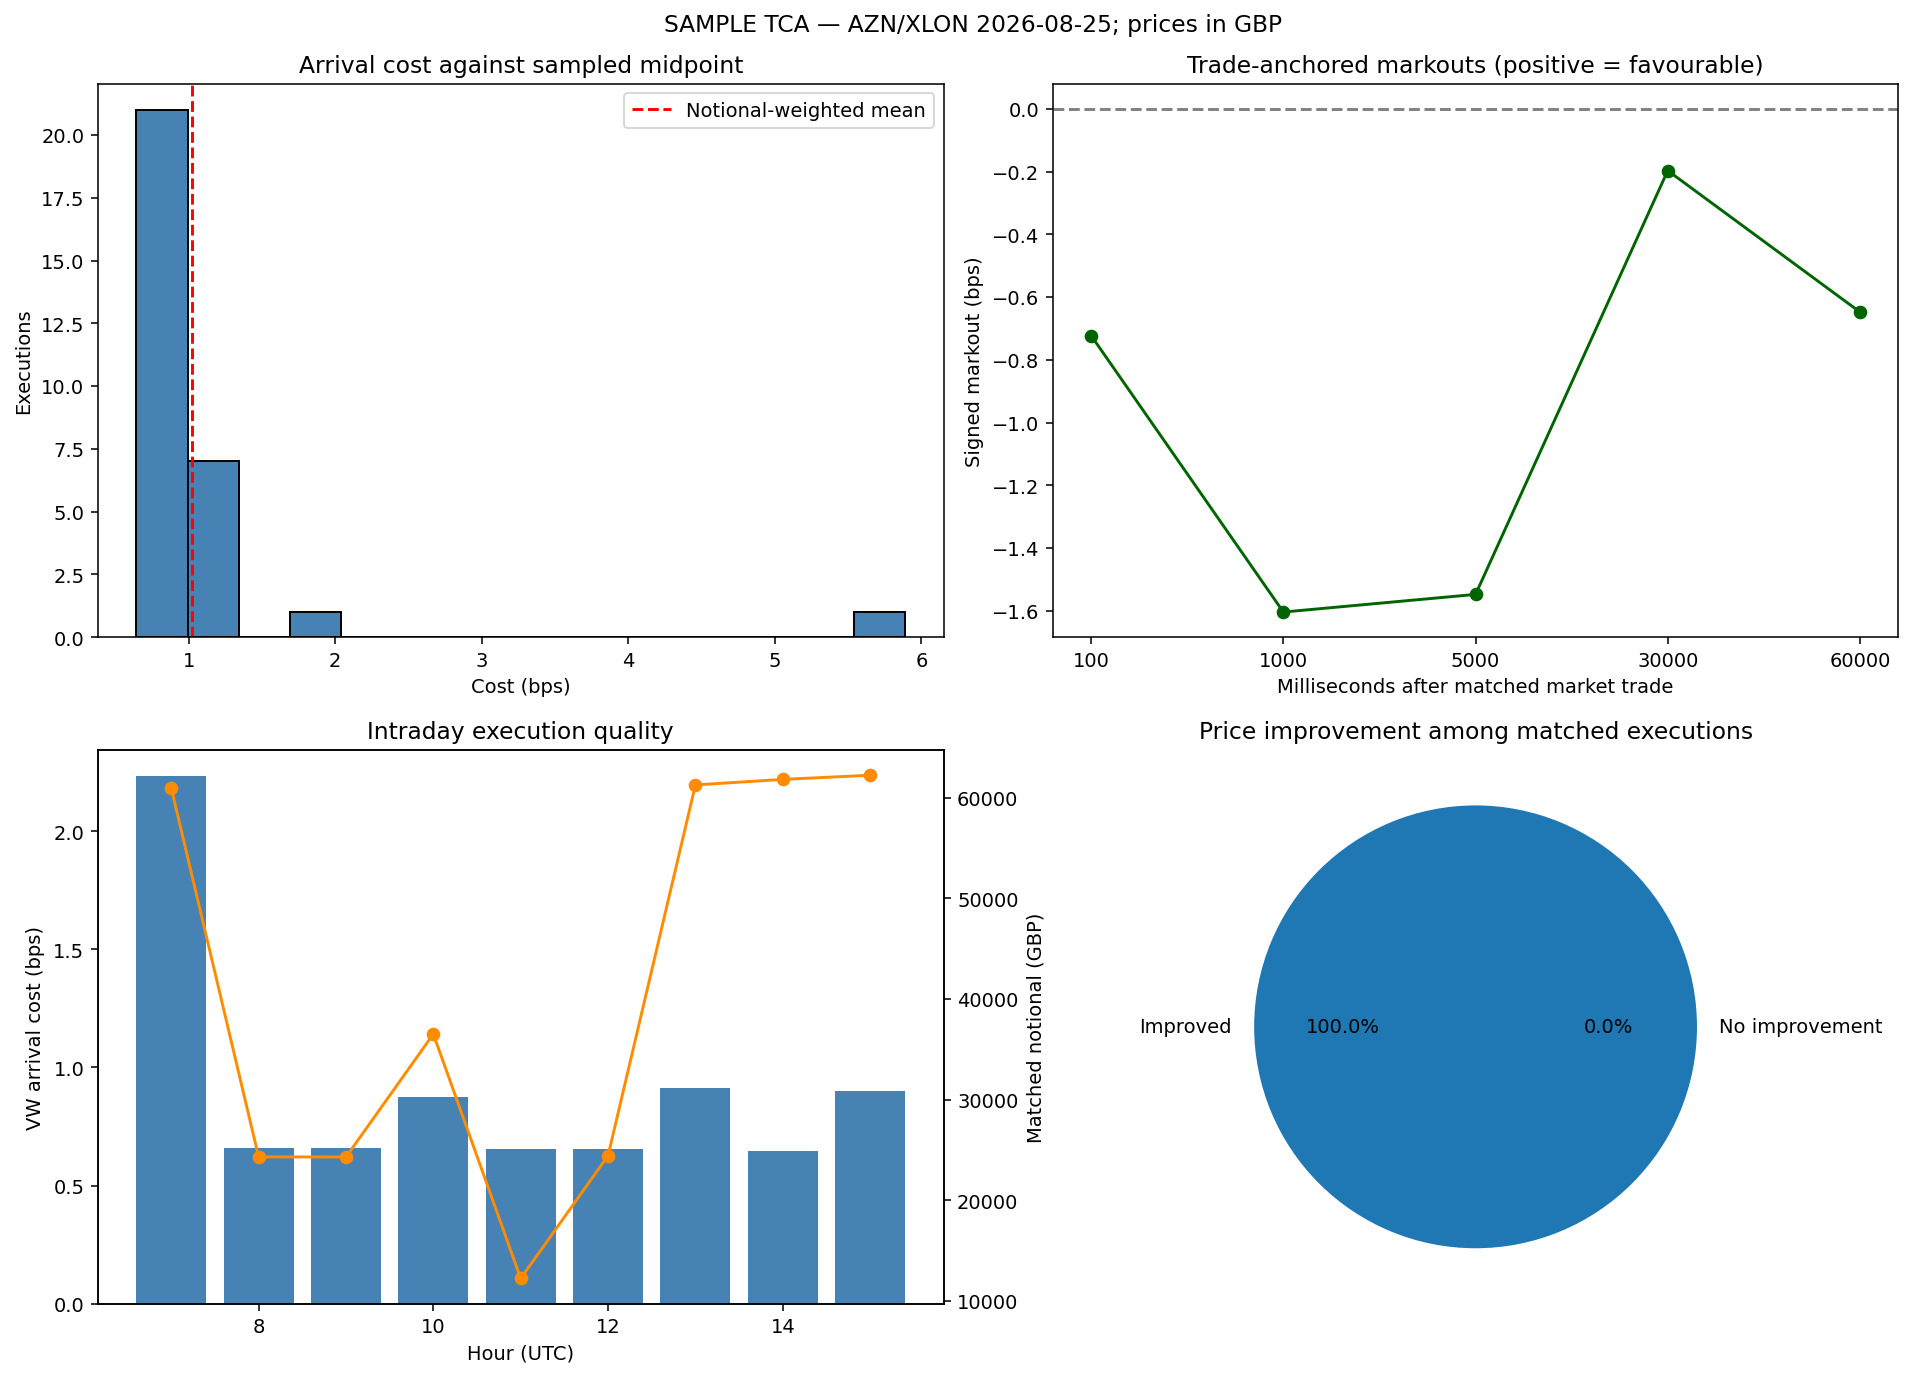

,Hour (UTC),AvgCostBps,Count,Notional (GBP)
0,7,2.232594,5,60934.2
1,8,0.658220,2,24308.0
2,9,0.658545,2,24296.0
3,10,0.876501,3,36510.0
4,11,0.654076,1,12231.8
5,12,0.654986,2,24428.0
6,13,0.914155,5,61258.2
7,14,0.647176,5,61807.8
8,15,0.899937,5,62222.6


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(tca_pdf["ArrivalCostBps"], bins=15, color="steelblue", edgecolor="black")
axes[0, 0].axvline(weighted_tca_metric(tca_pdf, "ArrivalCostBps"), color="red", linestyle="--", label="Notional-weighted mean")
axes[0, 0].set(title="Arrival cost against sampled midpoint", xlabel="Cost (bps)", ylabel="Executions")
axes[0, 0].legend()
axes[0, 1].plot([str(h) for h in HORIZONS_MS], markout_summary["markout_bps"], marker="o", color="darkgreen")
axes[0, 1].axhline(0, color="grey", linestyle="--")
axes[0, 1].set(title="Trade-anchored markouts (positive = favourable)",
               xlabel="Milliseconds after matched market trade", ylabel="Signed markout (bps)")
axes[1, 0].bar(intraday_agg["Hour"], intraday_agg["AvgCostBps"], color="steelblue")
axes[1, 0].set(title="Intraday execution quality", xlabel="Hour (UTC)", ylabel="VW arrival cost (bps)")
notional_axis = axes[1, 0].twinx()
notional_axis.plot(intraday_agg["Hour"], intraday_agg["Notional"], color="darkorange", marker="o")
notional_axis.set_ylabel(f"Matched notional ({PRICE_CURRENCY})")
improved = int(tca_pdf["PriceImprovement"].gt(0).sum())
axes[1, 1].pie([improved, len(tca_pdf) - improved], labels=["Improved", "No improvement"], autopct="%.1f%%")
axes[1, 1].set_title("Price improvement among matched executions")
fig.suptitle(f"{METHOD} TCA — {TICKER}/{MIC_TRADES} {ANALYSIS_DATE}; prices in {PRICE_CURRENCY}")
plt.tight_layout()
plt.show()
display(intraday_agg.rename(columns={"Hour": "Hour (UTC)", "Notional": f"Notional ({PRICE_CURRENCY})"}))

### 6. Execution-level detail
Retain `result_df` for every supplied execution, including unmatched rows.
The best/worst comparison below covers matched executions only.

In [19]:
detail_columns = ["exec_id", "timestamp", "market_timestamp", "quote_age_ms", "side", "quantity", "price",
                  "MarketMid", "ArrivalCostBps", "PriceImprovementBps", "Markout_60000msBps"]
print("Highest arrival costs:")
display(tca_pdf.nlargest(5, "ArrivalCostBps")[detail_columns])
print("Lowest arrival costs:")
display(tca_pdf.nsmallest(5, "ArrivalCostBps")[detail_columns])

Highest arrival costs:
Lowest arrival costs:


,exec_id,timestamp,market_timestamp,quote_age_ms,side,quantity,price,MarketMid,ArrivalCostBps,PriceImprovementBps,Markout_60000msBps
0,EXEC_00001,2026-08-25 07:00:03.772000001+00:00,2026-08-25 07:00:03.772000+00:00,0.000001,buy,100,122.342,122.27,5.888607,1.472152,-32.060195
1,EXEC_00002,2026-08-25 07:03:03.793000001+00:00,2026-08-25 07:03:03.793000+00:00,0.000001,sell,100,121.646,121.67,1.972549,0.493137,9.533985
10,EXEC_00011,2026-08-25 10:32:36.451000001+00:00,2026-08-25 10:32:36.451000+00:00,0.000001,buy,100,121.456,121.44,1.317523,0.329381,-3.787879
2,EXEC_00003,2026-08-25 07:11:38.136000001+00:00,2026-08-25 07:11:38.136000+00:00,0.000001,buy,100,121.716,121.70,1.314708,0.328677,5.258833
4,EXEC_00005,2026-08-25 07:45:45.517000001+00:00,2026-08-25 07:45:45.517000+00:00,0.000001,buy,100,121.836,121.82,1.313413,0.328353,-2.134297


,exec_id,timestamp,market_timestamp,quote_age_ms,side,quantity,price,MarketMid,ArrivalCostBps,PriceImprovementBps,Markout_60000msBps
28,EXEC_00029,2026-08-25 15:25:51.244000001+00:00,2026-08-25 15:25:51.244000+00:00,0.000001,buy,100,124.598,124.59,0.642106,0.160527,3.371057
27,EXEC_00028,2026-08-25 15:19:36.410000001+00:00,2026-08-25 15:19:36.410000+00:00,0.000001,sell,100,124.482,124.49,0.642622,0.160655,-0.642622
26,EXEC_00027,2026-08-25 15:13:26.190000001+00:00,2026-08-25 15:13:26.190000+00:00,0.000001,buy,100,124.378,124.37,0.643242,0.160810,1.768915
24,EXEC_00025,2026-08-25 14:50:30.223000001+00:00,2026-08-25 14:50:30.223000+00:00,0.000001,buy,100,123.798,123.79,0.646256,0.161564,1.777203
22,EXEC_00023,2026-08-25 14:27:38.060000001+00:00,2026-08-25 14:27:38.060000+00:00,0.000001,buy,100,123.678,123.67,0.646883,0.161721,7.439153
